# Integrating Kamath 2022 and Siletti 2023 dopaminergic neurons (DA) with `scanpy`, `BBKNN` and `ingest`

Two public Parkinson's disease (PD) single-nucleus RNA-seq datasets of the human midbrain, ~10k cells each:

| Source | Role |
|---|---|
| **Kamath et al. 2022** (*Nat Neurosci*): substantia nigra, 10 DA neuron subtypes + other cell types | Annotated **reference** |
| **Siletti et al. 2023** (*Science*): whole-brain atlas. Here using substantia nigra and red nucleus to compare apples-to-apples vs. the Kamath dataset); DA neurons labelled via the Allen Brain Cell Atlas (`DA VGLUT2`) | **"New" dataset** to annotate |

We compare three views of the same cells:

1. **Uncorrected**: PCA → neighbours → UMAP on the merged data (shows the batch effect)
2. **BBKNN**: batch-balanced neighbours across sources → UMAP

We also run a **Differential gene expression** analiysis of DA neurons from PD patients (case) vs. healthy individuals (control).

**Inputs:**    
`data/kamath/intermediate/*h5ad` and `data/siletti/intermediate/*h5ad` files produced by: `scripts/01_download_kamath_siletti.py` and `scripts/02_downsample_kamath_siletti.py`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import bbknn
from scipy.stats import mannwhitneyu
import plotly.express as px

repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
sys.path.insert(0, str(repo_root / "utils"))
from _da_neurons_utils import (
    KAMATH_DA_MARKER_SYMBOLS,
    DEFAULT_CELLS_PER_SOURCE,
    DEFAULT_KAMATH_DA_PER_SUBTYPE,
    DEFAULT_KAMATH_NON_DA_MIN,
    OUTPUT_DIR,
    kamath_cache_paths,
    siletti_cache_paths,
    marker_ensembl_ids,
    chdir_to_repo_root,
)

chdir_to_repo_root()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(4, 4), facecolor="white")
t_start = time.perf_counter()

[INFO] Changing working directory to repo root: /Users/jdime/da_neurons_analysis


## Parameters

The downsampling values must match those used in `02_downsample_kamath_siletti.py` (they locate its caches).
BBKNN uses the exact `cKDTree` neighbour search: fast at this size, and immune to broken locally
compiled `annoy` builds (see the README).

In [2]:
CELLS_PER_SOURCE = DEFAULT_CELLS_PER_SOURCE            # 10,000
KAMATH_DA_PER_SUBTYPE = DEFAULT_KAMATH_DA_PER_SUBTYPE  # 300
KAMATH_NON_DA_MIN = DEFAULT_KAMATH_NON_DA_MIN          # 50
USE_QC_FILTERED = True     # postQC caches; False -> preQC

N_HVGS = 3000              # highly variable genes (Pearson residuals, per source)
N_PCS = 50
BBKNN_BATCH_KEY = "source"  # or "batch" (donor/sample)
BBKNN_COMPUTATION = "cKDTree"

DE_GROUPS = ("PD", "Control")  # (test, reference) values of condition_id
DE_MIN_PCT = 0.10          # test genes detected in >= 10% of cells of either group
DE_MIN_DONOR_CELLS = 10    # donors with fewer DA cells are left out of the donor-level check
DE_FDR = 0.05             # adjusted p-value cutoff
DE_MIN_LFC = 1.0          # |log2 fold change| cutoff for the volcano plot calls

WRITE_OUTPUTS = False      # True: save the integrated H5AD and tables under outputs/

## 1. Load and merge the downsampled datasets

Each dataset is an **AnnData** H5AD written by `02_downsample_kamath_siletti.py`.
The downsampling values locate the matching files.

In [3]:
qc_index = 1 if USE_QC_FILTERED else 0
kamath_path = kamath_cache_paths(CELLS_PER_SOURCE, KAMATH_DA_PER_SUBTYPE, KAMATH_NON_DA_MIN)[qc_index]
siletti_path = siletti_cache_paths(CELLS_PER_SOURCE)[qc_index]

kamath = sc.read_h5ad(kamath_path)
siletti = sc.read_h5ad(siletti_path)
print(f"Kamath:  {kamath.n_obs:,} cells x {kamath.n_vars:,} genes")
print(f"Siletti: {siletti.n_obs:,} cells x {siletti.n_vars:,} genes")

Kamath:  9,959 cells x 33,295 genes
Siletti: 9,959 cells x 58,232 genes


In [4]:
kamath.obs.head()

,author_cell_type,donor_id,author_Donor_PMI,author_Cause_of_Death,author_FACS_Classification,assay_ontology_term_id,cell_type_ontology_term_id,development_stage_ontology_term_id,disease_ontology_term_id,self_reported_ethnicity_ontology_term_id,...,condition_id,is_da,kamath_cell_type,kamath_author_cell_type,kamath_da_subtype,original_barcode,total_counts,n_genes,pct_counts_mt,doublet_score
index,,,,,,,,,,,,,,,,,,,,,
kamath_pPDsHSrSNxi3298d200429DAPIA_AATGAAGTCACACCGG-1,Astro_GJB6_OXTR,3298,22.0,Prostate cancer,Negative,EFO:0009922,CL:0000127,HsapDv:0000173,PATO:0000461,unknown,...,Control,False,astrocyte,Astro_GJB6_OXTR,NaN,pPDsHSrSNxi3298d200429DAPIA_AATGAAGTCACACCGG-1,2640,1346,1.704545,0.039326
kamath_pPDsHSrSNxi3298d200429DAPIA_CAGCCAGCACTTACAG-1,Astro_GJB6_OXTR,3298,22.0,Prostate cancer,Negative,EFO:0009922,CL:0000127,HsapDv:0000173,PATO:0000461,unknown,...,Control,False,astrocyte,Astro_GJB6_OXTR,NaN,pPDsHSrSNxi3298d200429DAPIA_CAGCCAGCACTTACAG-1,2386,1245,4.233026,0.033079
kamath_pPDsHSrSNxi3298d200429DAPIB_TCCACCACACTTGGGC-1,Astro_GJB6_OXTR,3298,22.0,Prostate cancer,Negative,EFO:0009922,CL:0000127,HsapDv:0000173,PATO:0000461,unknown,...,Control,False,astrocyte,Astro_GJB6_OXTR,NaN,pPDsHSrSNxi3298d200429DAPIB_TCCACCACACTTGGGC-1,2258,1234,2.435784,0.039326
kamath_pPDsHSrSNxi3298d200429PosA_GGTTCTCTCTAGTCAG-1,Astro_GJB6_OXTR,3298,22.0,Prostate cancer,Positive,EFO:0009922,CL:0000127,HsapDv:0000173,PATO:0000461,unknown,...,Control,False,astrocyte,Astro_GJB6_OXTR,NaN,pPDsHSrSNxi3298d200429PosA_GGTTCTCTCTAGTCAG-1,1690,922,2.130178,0.039326
kamath_pPDsHSrSNxi3298d200429DAPIB_TCTCAGCGTCGCCACA-1,Astro_GJB6_OXTR,3298,22.0,Prostate cancer,Negative,EFO:0009922,CL:0000127,HsapDv:0000173,PATO:0000461,unknown,...,Control,False,astrocyte,Astro_GJB6_OXTR,NaN,pPDsHSrSNxi3298d200429DAPIB_TCTCAGCGTCGCCACA-1,4451,1970,2.201752,0.033079


In [5]:
siletti.obs.head()

,roi,disease_ontology_term_id,self_reported_ethnicity_ontology_term_id,assay_ontology_term_id,sex_ontology_term_id,development_stage_ontology_term_id,donor_id,suspension_type,dissection,fraction_mitochondrial,...,siletti_supercluster,siletti_allen_neurotransmitter,siletti_allen_supercluster,siletti_allen_cluster,siletti_allen_subcluster,original_barcode,total_counts,n_genes,pct_counts_mt,doublet_score
CellID,,,,,,,,,,,,,,,,,,,,,
siletti_10X194_5:TTAGGCATCGTAATGC,Human SN-RN,PATO:0000461,unknown,EFO:0009922,PATO:0000384,HsapDv:0000144,H18.30.002,nucleus,"Midbrain (M) - Substantia Nigra, Red Nucleus, ...",0.002652,...,Oligodendrocyte,None,Oligodendrocyte,Oligo_40,Oligo_40_3011,10X194_5:TTAGGCATCGTAATGC,5275,2374,0.227488,0.085561
siletti_10X236_1:AACGGGACAACTGGTT,Human SN-RN,PATO:0000461,unknown,EFO:0009922,PATO:0000384,HsapDv:0000136,H19.30.001,nucleus,"Midbrain (M) - Substantia Nigra, Red Nucleus, ...",0.001428,...,Oligodendrocyte,None,Oligodendrocyte,Oligo_40,Oligo_40_3013,10X236_1:AACGGGACAACTGGTT,2794,1412,0.143164,0.033467
siletti_10X236_1:TGTCCTGAGGCTCAAG,Human SN-RN,PATO:0000461,unknown,EFO:0009922,PATO:0000384,HsapDv:0000136,H19.30.001,nucleus,"Midbrain (M) - Substantia Nigra, Red Nucleus, ...",0.001002,...,Oligodendrocyte,None,Oligodendrocyte,Oligo_40,Oligo_40_3013,10X236_1:TGTCCTGAGGCTCAAG,3976,1924,0.100604,0.030612
siletti_10X176_2:GCCGATGTCACTTGTT,Human SN-RN,PATO:0000461,unknown,EFO:0009922,PATO:0000384,HsapDv:0000144,H18.30.002,nucleus,"Midbrain (M) - Substantia Nigra, Red Nucleus, ...",0.014861,...,Oligodendrocyte,None,Oligodendrocyte,Oligo_40,Oligo_40_3012,10X176_2:GCCGATGTCACTTGTT,7866,2924,1.144165,0.037975
siletti_10X236_1:CTCAATTTCATCGGGC,Human SN-RN,PATO:0000461,unknown,EFO:0009922,PATO:0000384,HsapDv:0000136,H19.30.001,nucleus,"Midbrain (M) - Substantia Nigra, Red Nucleus, ...",0.000000,...,Oligodendrocyte,None,Oligodendrocyte,Oligo_40,Oligo_40_3013,10X236_1:CTCAATTTCATCGGGC,3429,1696,0.000000,0.025641


Each source carries its own annotation columns. Keep a common set (missing ones become `NaN`),
put the raw counts in `X`, and concatenate the cells, keeping only the genes (Ensembl IDs)
present in both, and the gene annotation columns the two sources share.

In [6]:
shared_obs = ["source", "batch", "condition_id", "is_da", "original_barcode"]
kamath_obs = ["kamath_cell_type", "kamath_author_cell_type", "kamath_da_subtype"]
siletti_obs = [
    "siletti_cell_type", "siletti_supercluster", "siletti_region",
    "siletti_allen_neurotransmitter", "siletti_allen_supercluster",
    "siletti_allen_cluster", "siletti_allen_subcluster",
]
obs_columns = shared_obs + kamath_obs + siletti_obs
for source in (kamath, siletti):
    source.obs = source.obs.reindex(columns=obs_columns)
    source.X = source.layers["counts"]

merged = ad.concat([kamath, siletti], join="inner")  # inner: genes present in both
# Gene annotation columns both sources share (values identical; their categorical dtypes
# differ, so concat's merge="same" would drop them)
shared_var = kamath.var.columns.intersection(siletti.var.columns)
merged.var = kamath.var.loc[merged.var_names, shared_var]
merged.obs["is_da"] = merged.obs["is_da"].astype(bool)
merged.obs["da_label"] = pd.Categorical(np.where(merged.obs["is_da"], "DA", "non-DA"))
for col in obs_columns[1:]:
    if merged.obs[col].dtype == object:
        merged.obs[col] = merged.obs[col].astype("category")

print(f"Merged: {merged.n_obs:,} cells x {merged.n_vars:,} shared genes")
pd.crosstab(merged.obs["source"], merged.obs["da_label"])

Merged: 19,918 cells x 32,776 shared genes


da_label,DA,non-DA
source,,
kamath,2976,6983
siletti,789,9170


### The AnnData object

- `obs`: one row per **cell** (annotations)
- `var`: one row per **gene** (Ensembl ID index; symbol, type and length from CELLxGENE)
- `X`: the cells × genes matrix (sparse raw counts here); `layers` holds other versions of it

In [7]:
merged

AnnData object with n_obs × n_vars = 19918 × 32776
    obs: 'source', 'batch', 'condition_id', 'is_da', 'original_barcode', 'kamath_cell_type', 'kamath_author_cell_type', 'kamath_da_subtype', 'siletti_cell_type', 'siletti_supercluster', 'siletti_region', 'siletti_allen_neurotransmitter', 'siletti_allen_supercluster', 'siletti_allen_cluster', 'siletti_allen_subcluster', 'da_label'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    layers: 'counts'

In [8]:
merged.obs.head()

,source,batch,condition_id,is_da,original_barcode,kamath_cell_type,kamath_author_cell_type,kamath_da_subtype,siletti_cell_type,siletti_supercluster,siletti_region,siletti_allen_neurotransmitter,siletti_allen_supercluster,siletti_allen_cluster,siletti_allen_subcluster,da_label
kamath_pPDsHSrSNxi3298d200429DAPIA_AATGAAGTCACACCGG-1,kamath,kamath_3298,Control,False,pPDsHSrSNxi3298d200429DAPIA_AATGAAGTCACACCGG-1,astrocyte,Astro_GJB6_OXTR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,non-DA
kamath_pPDsHSrSNxi3298d200429DAPIA_CAGCCAGCACTTACAG-1,kamath,kamath_3298,Control,False,pPDsHSrSNxi3298d200429DAPIA_CAGCCAGCACTTACAG-1,astrocyte,Astro_GJB6_OXTR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,non-DA
kamath_pPDsHSrSNxi3298d200429DAPIB_TCCACCACACTTGGGC-1,kamath,kamath_3298,Control,False,pPDsHSrSNxi3298d200429DAPIB_TCCACCACACTTGGGC-1,astrocyte,Astro_GJB6_OXTR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,non-DA
kamath_pPDsHSrSNxi3298d200429PosA_GGTTCTCTCTAGTCAG-1,kamath,kamath_3298,Control,False,pPDsHSrSNxi3298d200429PosA_GGTTCTCTCTAGTCAG-1,astrocyte,Astro_GJB6_OXTR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,non-DA
kamath_pPDsHSrSNxi3298d200429DAPIB_TCTCAGCGTCGCCACA-1,kamath,kamath_3298,Control,False,pPDsHSrSNxi3298d200429DAPIB_TCTCAGCGTCGCCACA-1,astrocyte,Astro_GJB6_OXTR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,non-DA


In [9]:
# Raw counts of DA marker genes in 5 Kamath DA neurons (X is sparse; .toarray() makes it dense)
markers = ["TH", "SLC6A3", "SOX6", "CALB1", "AGTR1"]
gene_idx = [merged.var["feature_name"].tolist().index(g) for g in markers]
cell_idx = np.flatnonzero(merged.obs["is_da"].to_numpy())[:5]
pd.DataFrame(merged.X[cell_idx][:, gene_idx].toarray(), index=merged.obs_names[cell_idx], columns=markers)

,TH,SLC6A3,SOX6,CALB1,AGTR1
kamath_pPDsHSrSNxi3298d200429DAPIB_CTCAATTTCCGAGGCT-1,0,2,1,0,0
kamath_pPDsHSrSNxi3322d200429PosA_TCTATCAAGATACCAA-1,9,9,15,0,4
kamath_pPDsHSrSNxi3322d200429PosA_CACGAATAGCATTGTC-1,3,9,24,0,15
kamath_pPDsHSrSNxi3322d200429PosA_AGTCATGGTCAAAGAT-1,0,8,1,0,6
kamath_pPDsHSrSNxi3322d200429PosA_TGACGCGCACGACGAA-1,5,9,13,0,4


## 2. Preprocess

Normalise to 10k counts per cell, log-transform, and keep the highly variable genes (HVGs)
plus the 17 Kamath DA marker genes, so DA subtypes stay resolvable.

In [10]:
sc.pp.normalize_total(merged, target_sum=1e4)
sc.pp.log1p(merged)
sc.experimental.pp.highly_variable_genes(
    merged, flavor="pearson_residuals", n_top_genes=N_HVGS, layer="counts", batch_key="source",
)
da_markers = marker_ensembl_ids(merged, KAMATH_DA_MARKER_SYMBOLS)
keep = merged.var["highly_variable"].to_numpy() | merged.var_names.isin(da_markers)
adata = merged[:, keep].copy()
print(f"Gene panel: {merged.n_vars:,} -> {adata.n_vars:,} genes")

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Gene panel: 32,776 -> 3,008 genes


## 3. Uncorrected integration

Cells separate by **source** before biology: the batch effect.

In [11]:
sc.pp.pca(adata, n_comps=N_PCS)
sc.pp.neighbors(adata, n_pcs=N_PCS)
sc.tl.umap(adata)
adata.obsm["X_umap_uncorrected"] = adata.obsm.pop("X_umap")

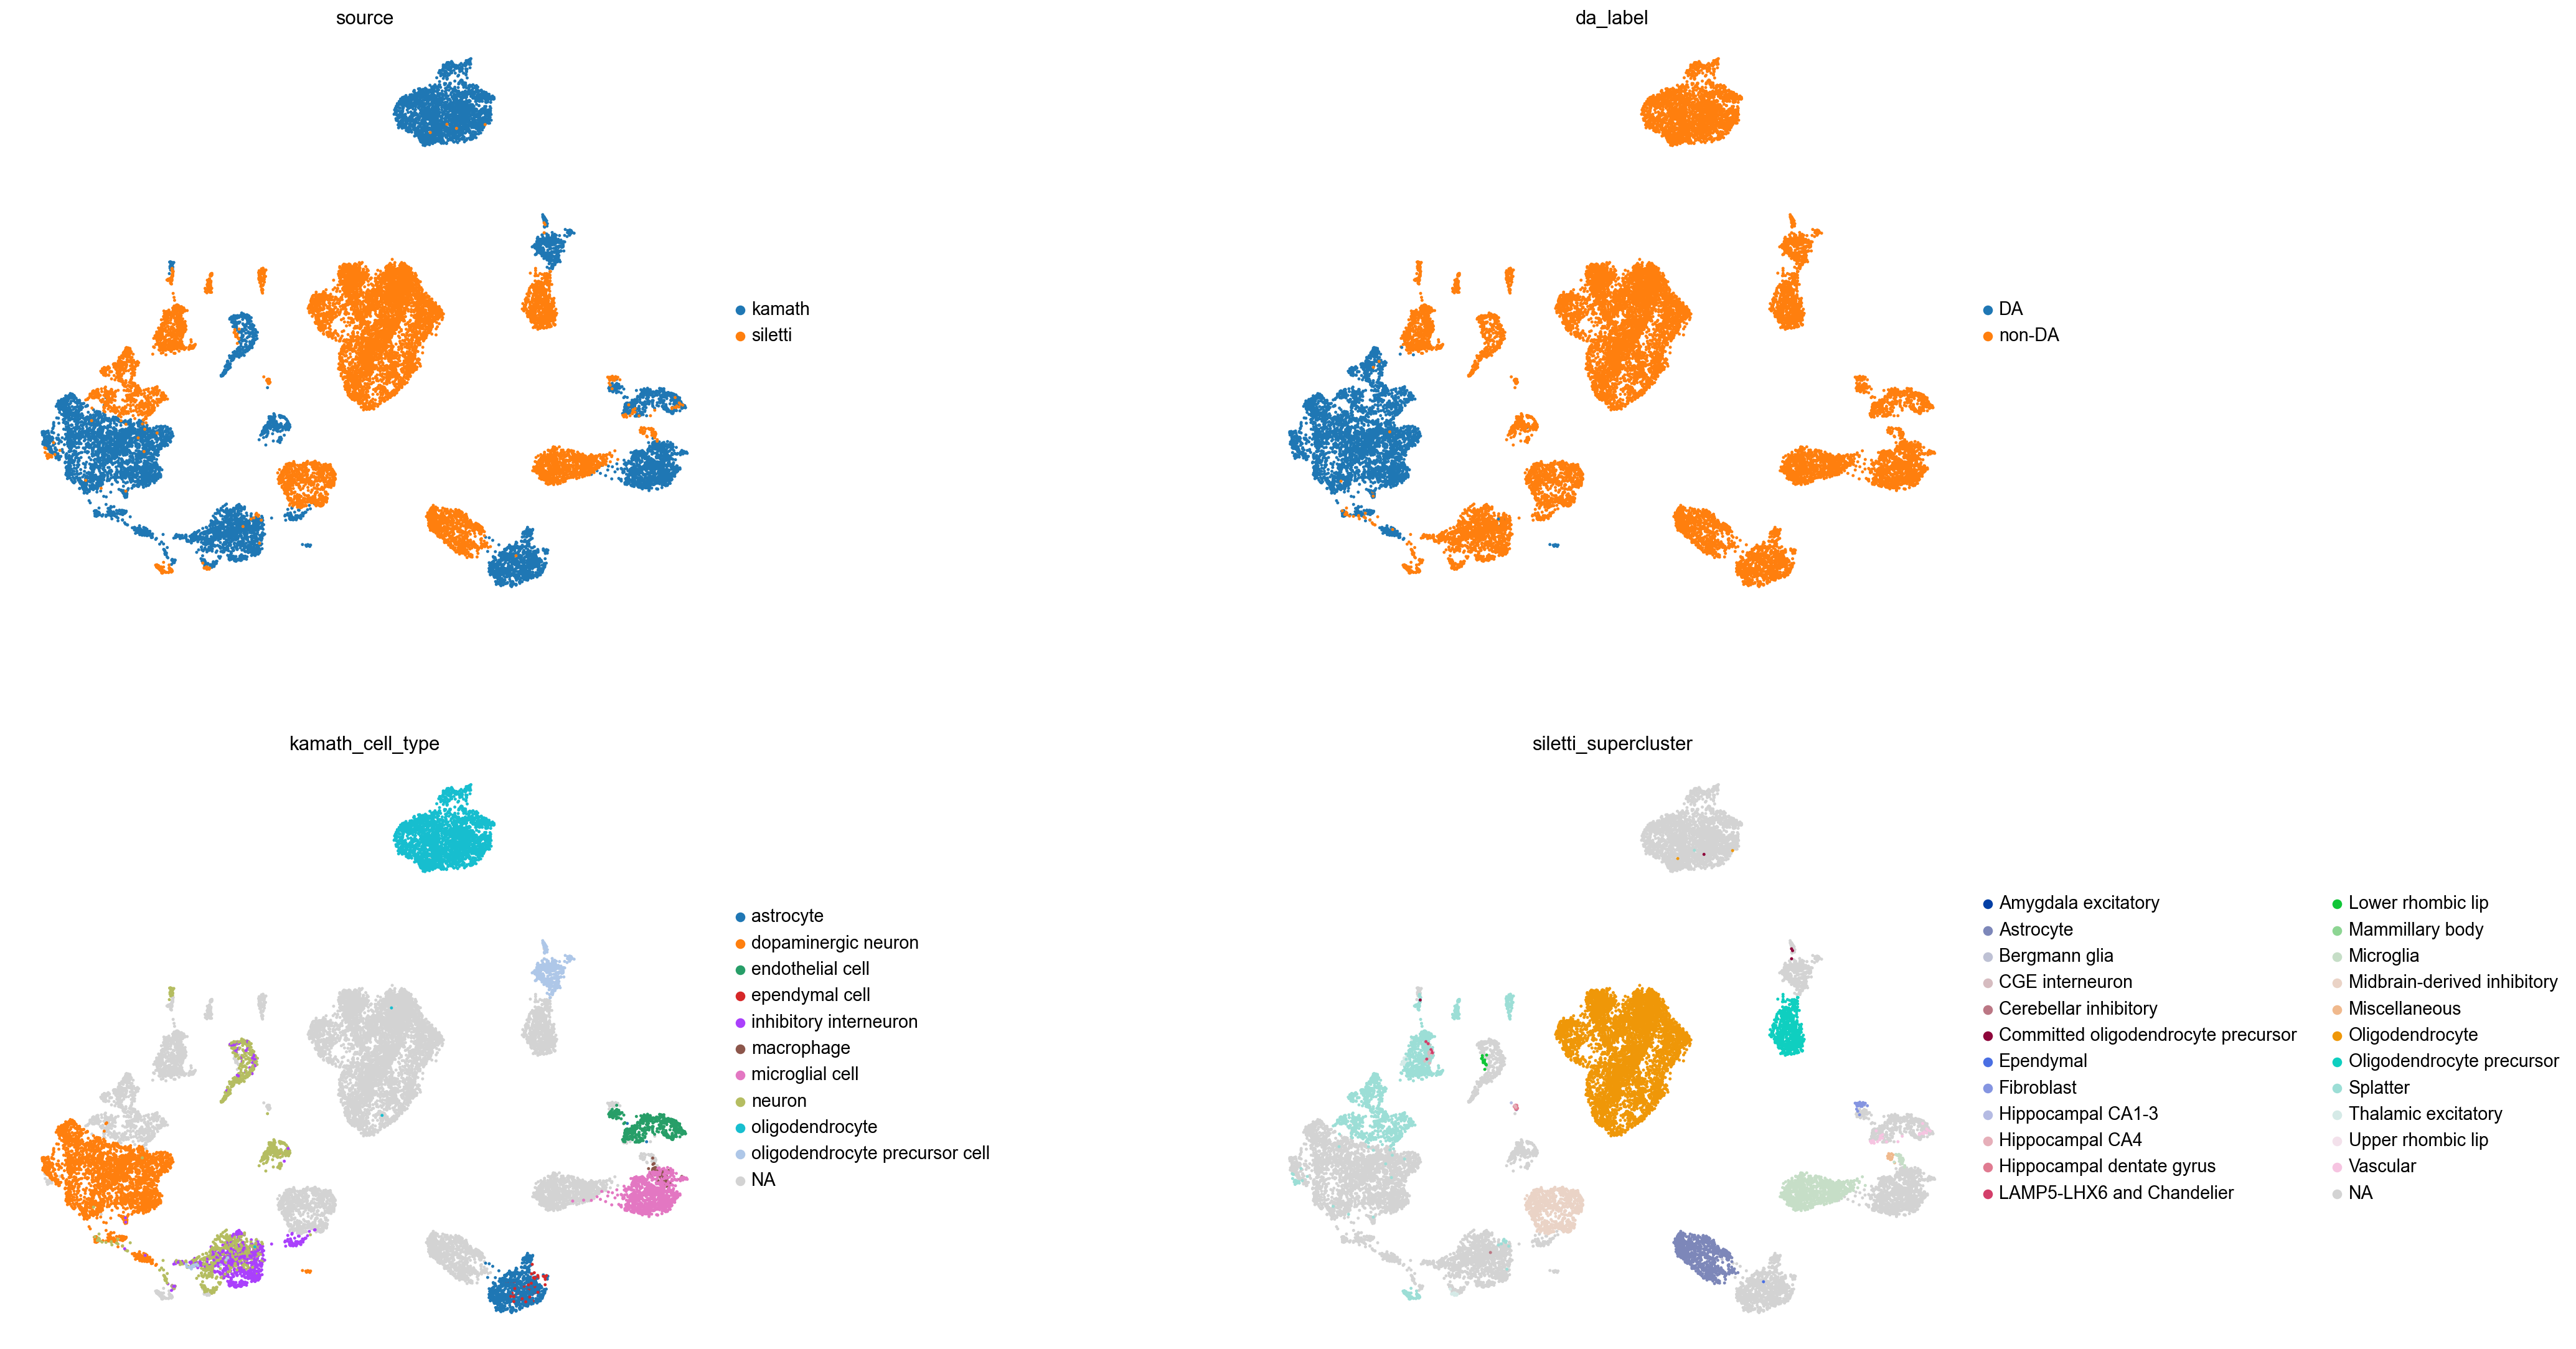

In [12]:
# plot
with plt.rc_context({"figure.figsize": (8, 8)}): # plot size
    sc.pl.embedding(adata, basis="X_umap_uncorrected",
                    color=["source", "da_label", "kamath_cell_type", "siletti_supercluster"],
                    wspace=0.6, ncols=2, size=20)

## 4. BBKNN

Note that now in the `source` UMAP plot, cells from the two studies (kamath and siletti) overlap with each other. This 

In [13]:
bbknn.bbknn(adata, batch_key=BBKNN_BATCH_KEY, computation=BBKNN_COMPUTATION, n_pcs=N_PCS)
sc.tl.umap(adata)
adata.obsm["X_umap_bbknn"] = adata.obsm.pop("X_umap")

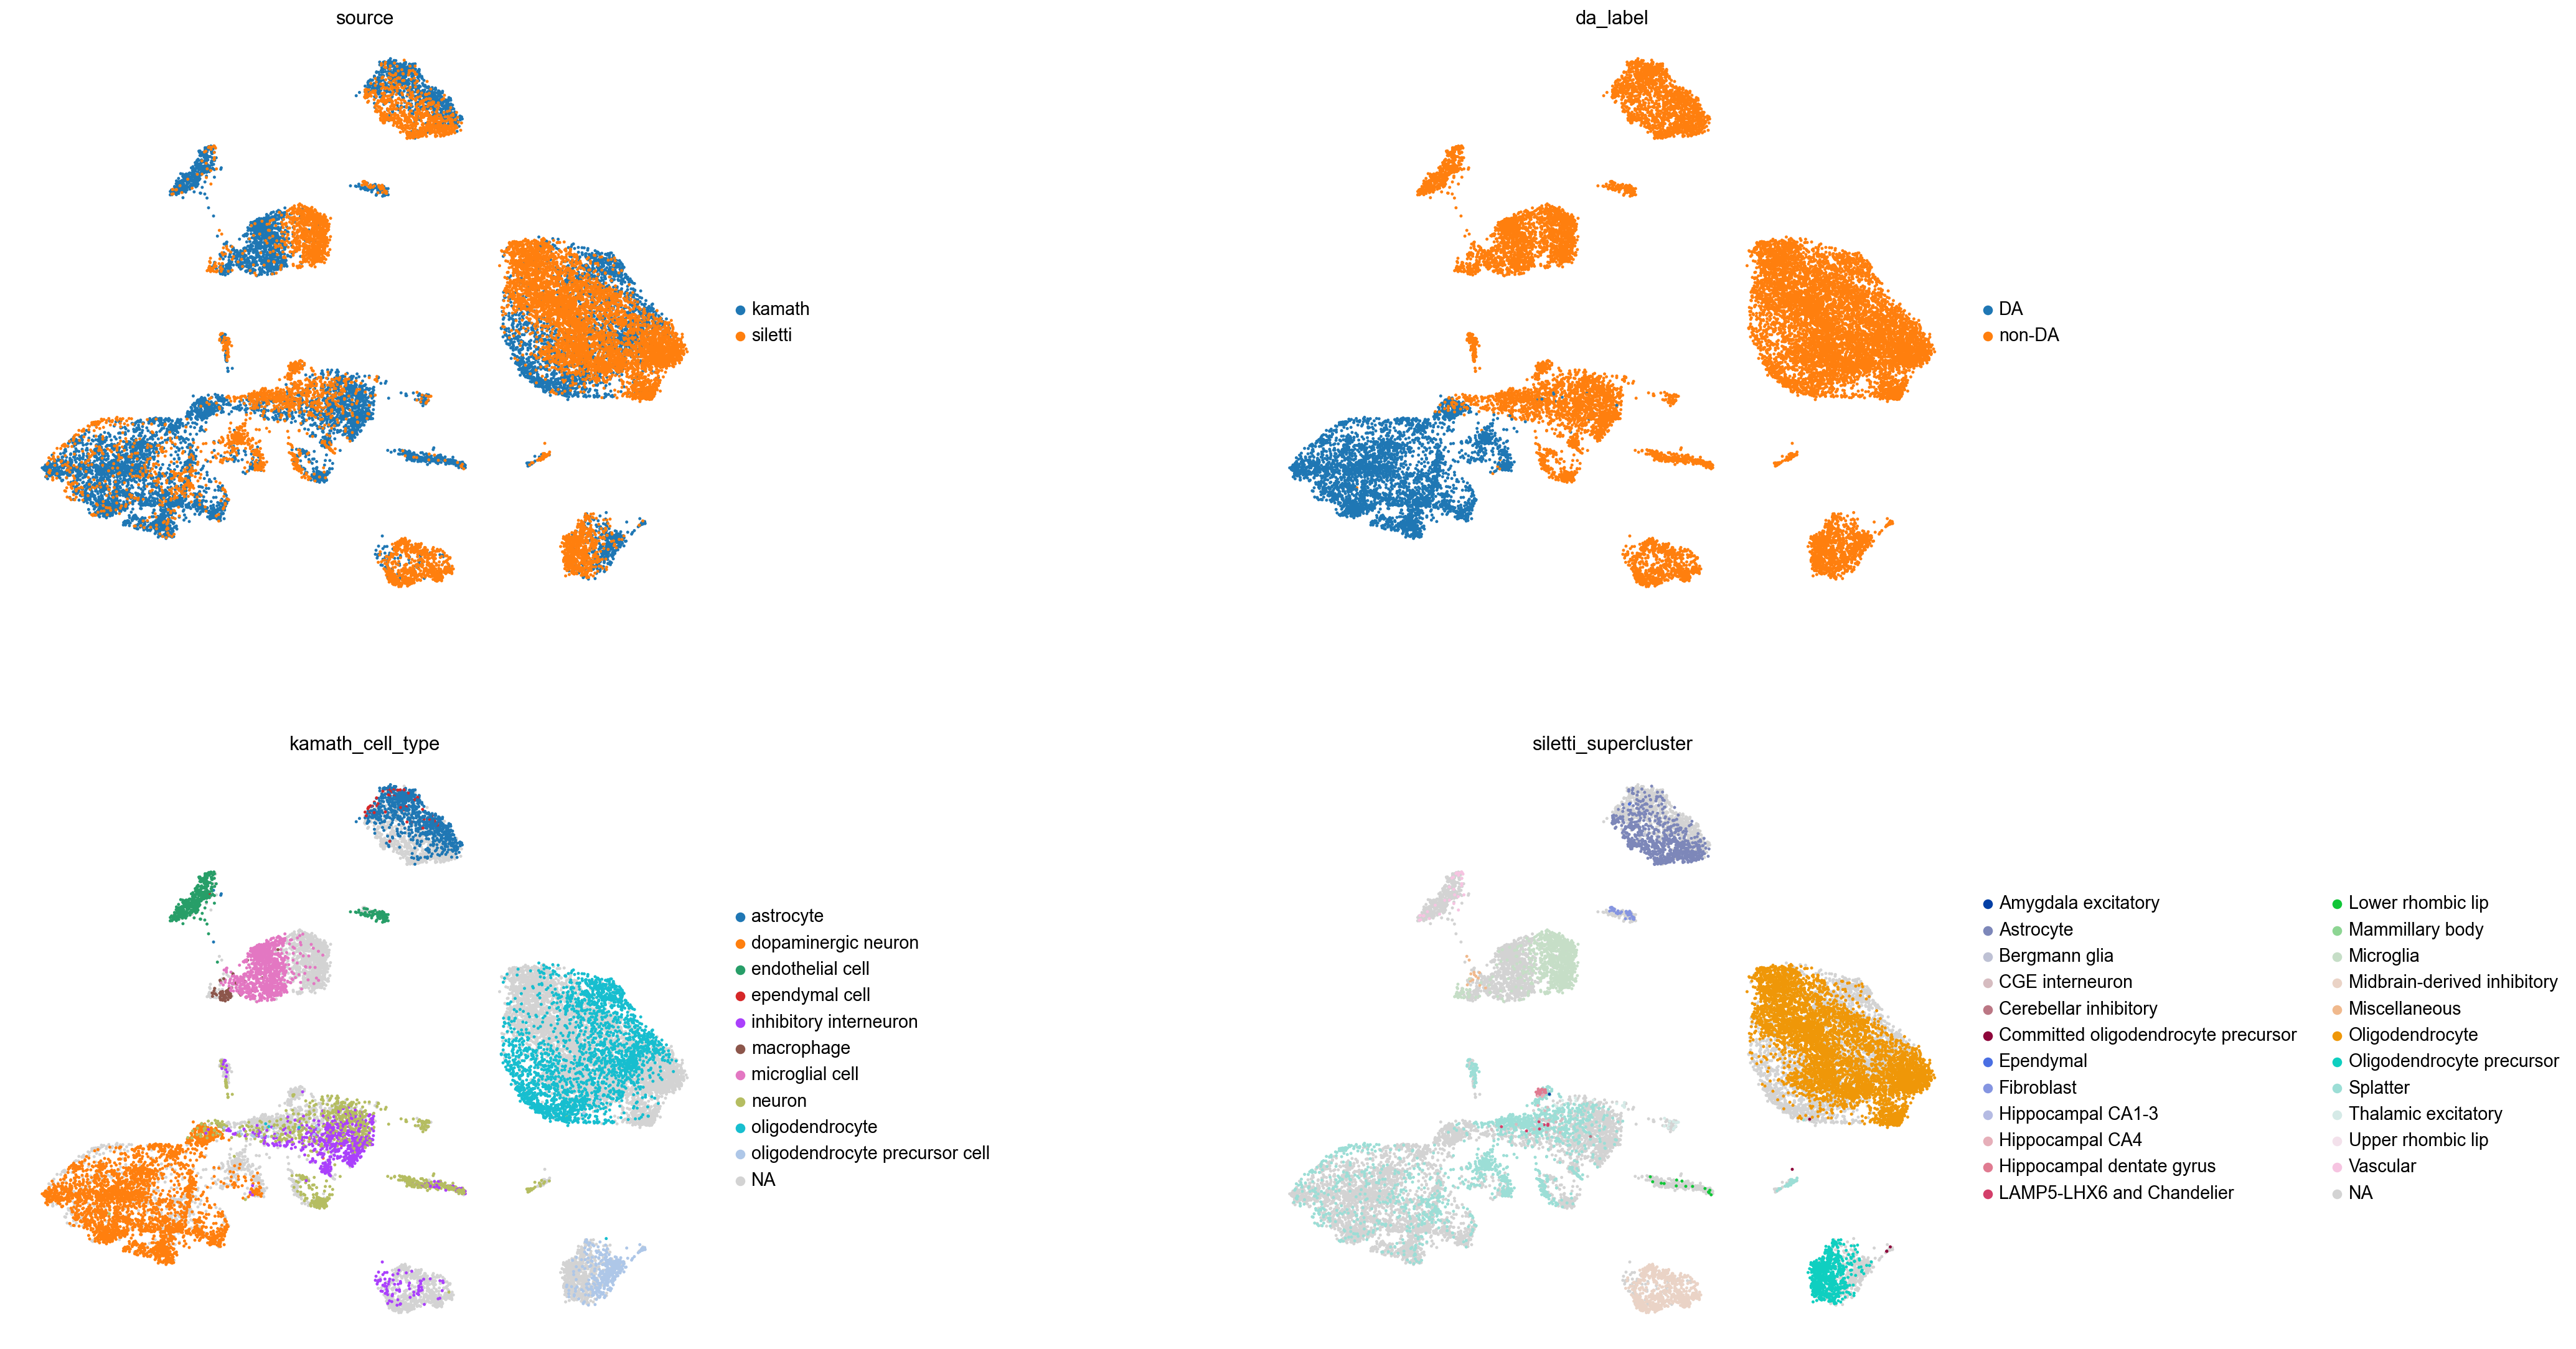

In [14]:
# Note that now, the 
with plt.rc_context({"figure.figsize": (8, 8)}):
    sc.pl.embedding(adata, basis="X_umap_bbknn",
                    color=["source", "da_label", "kamath_cell_type", "siletti_supercluster"],
                    wspace=0.6, ncols=2, size=20)

## 5. Differential expression: PD vs Control DA neurons from Kamath's dataset

Wilcoxon rank-sum test (`sc.tl.rank_genes_groups`) on log-normalised expression of
**Kamath DA neurons** only: Siletti has no PD donors, so adding its controls would
confound condition with source. All shared genes are tested (not only the HVG panel),
after dropping those detected in fewer than `DE_MIN_PCT` of the cells of both groups.

In [15]:
test_group, ref_group = DE_GROUPS
de_mask = ((merged.obs["source"] == "kamath") & merged.obs["is_da"]
           & merged.obs["condition_id"].isin(DE_GROUPS))
de = merged[de_mask.to_numpy()].copy()
de.obs["condition_id"] = pd.Categorical(de.obs["condition_id"].astype(str), categories=list(DE_GROUPS))

is_test = (de.obs["condition_id"] == test_group).to_numpy()
detected = de.X > 0
pct_test = np.asarray(detected[is_test].mean(axis=0)).ravel()
pct_ref = np.asarray(detected[~is_test].mean(axis=0)).ravel()
de = de[:, np.maximum(pct_test, pct_ref) >= DE_MIN_PCT].copy()

cells_per_donor = de.obs.groupby(["condition_id", "batch"], observed=True).size()
sc.tl.rank_genes_groups(de, groupby="condition_id", groups=[test_group], reference=ref_group,
                        method="wilcoxon", tie_correct=True, pts=True, key_added="de")
de_df = sc.get.rank_genes_groups_df(de, group=test_group, key="de", gene_symbols="feature_name")
de_df = de_df.drop(columns="group", errors="ignore").rename(columns={"names": "gene_id", "feature_name": "symbol"})

# Donor-level check: mean expression per donor, then Mann-Whitney across donors
donor_ok = cells_per_donor[cells_per_donor >= DE_MIN_DONOR_CELLS]
donor_condition = donor_ok.index.to_frame(index=False).set_index("batch")["condition_id"]
donor_means = sc.get.aggregate(de[de.obs["batch"].isin(donor_condition.index)],
                               by="batch", func="mean").to_df(layer="mean")
donor_means = donor_means.loc[donor_condition.index, de_df["gene_id"]]
donor_is_test = (donor_condition == test_group).to_numpy()
de_df["donor_delta"] = (donor_means[donor_is_test].mean() - donor_means[~donor_is_test].mean()).to_numpy()
de_df["donor_mwu_pval"] = mannwhitneyu(donor_means[donor_is_test], donor_means[~donor_is_test], axis=0).pvalue

sig = de_df["pvals_adj"] < 0.05
print(f"Donors in the donor-level check: {donor_is_test.sum()} {test_group}, {(~donor_is_test).sum()} {ref_group}")
print(f"Cell-level FDR < 0.05: {(sig & (de_df['logfoldchanges'] > 0)).sum():,} up, "
      f"{(sig & (de_df['logfoldchanges'] < 0)).sum():,} down in {test_group}")

column_order = ['symbol', 'gene_id', 'scores', 'logfoldchanges', 'pvals', 'pvals_adj',
                'pct_nz_group', 'donor_delta', 'donor_mwu_pval']

de_df = de_df[column_order]

print(f"{de.n_obs:,} DA neurons x {de.n_vars:,} genes tested")
cells_per_donor.groupby(level=0, observed=True).agg(["size", "sum", "max"]).set_axis(
    ["n_donors", "n_cells", "max_cells_one_donor"], axis=1)

Donors in the donor-level check: 3 PD, 7 Control
Cell-level FDR < 0.05: 4,137 up, 4,053 down in PD
2,436 DA neurons x 12,825 genes tested


,n_donors,n_cells,max_cells_one_donor
condition_id,,,
PD,6,475,358
Control,8,1961,785


In [16]:
# Tabular view of top differentially expressed genes in DA neurons
# The `up` table shows genes that show a higher expression in PD patients than healthy controls
# The `down` table shows genes that show a lower expression in PD patients than healthy controls
n_top = 5
display(de_df.head(n_top)) # up
display(de_df.sort_values("scores").head(n_top)) # down

,symbol,gene_id,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,donor_delta,donor_mwu_pval
0,RUNX1,ENSG00000159216,25.645281,3.424209,4.772979e-145,6.121346e-141,0.717895,0.384972,0.361935
1,SNX31,ENSG00000174226,25.313004,3.219992,2.297412e-141,1.473215e-137,0.669474,0.341135,0.171460
2,HIBCH,ENSG00000198130,24.622797,1.344539,7.201185e-134,3.078507e-130,0.976842,0.695184,0.254451
3,ZNF574,ENSG00000105732,24.588236,3.731269,1.687833e-133,5.411613e-130,0.610526,0.456107,0.254451
4,DCDC1,ENSG00000170959,24.570370,2.568609,2.620382e-133,6.721279e-130,0.850526,0.564617,0.022654


,symbol,gene_id,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,donor_delta,donor_mwu_pval
12824,LINC00632,ENSG00000203930,-19.624863,-0.673736,9.483156e-86,5.067562e-83,0.983158,-0.314058,0.068247
12823,ALDH1A1,ENSG00000165092,-19.448929,-3.283168,2.975858e-84,1.526615e-81,0.227368,-0.912733,0.022654
12822,TIAM2,ENSG00000146426,-18.694590,-1.363498,5.479087e-78,2.342310e-75,0.953684,-0.738278,0.022654
12821,SWAP70,ENSG00000133789,-17.410576,-2.246917,6.859152e-68,1.999287e-65,0.378947,-0.387691,0.022654
12820,SEMA5A,ENSG00000112902,-17.016041,-1.992760,6.245280e-65,1.511240e-62,0.427368,-0.379793,0.022654


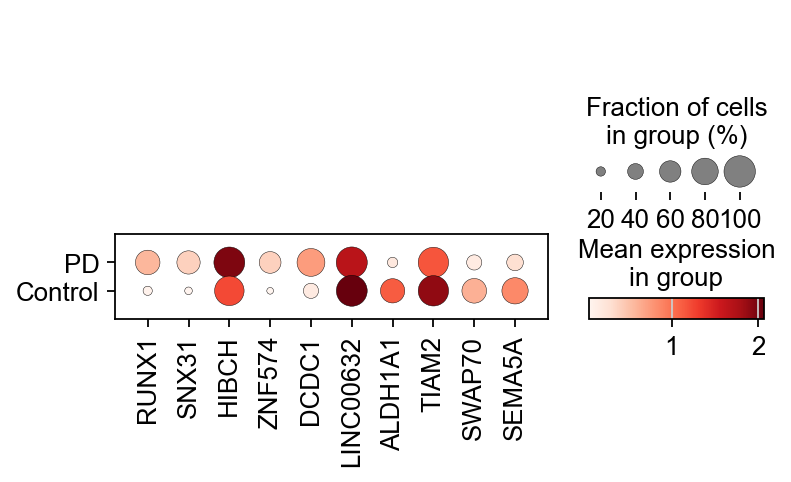

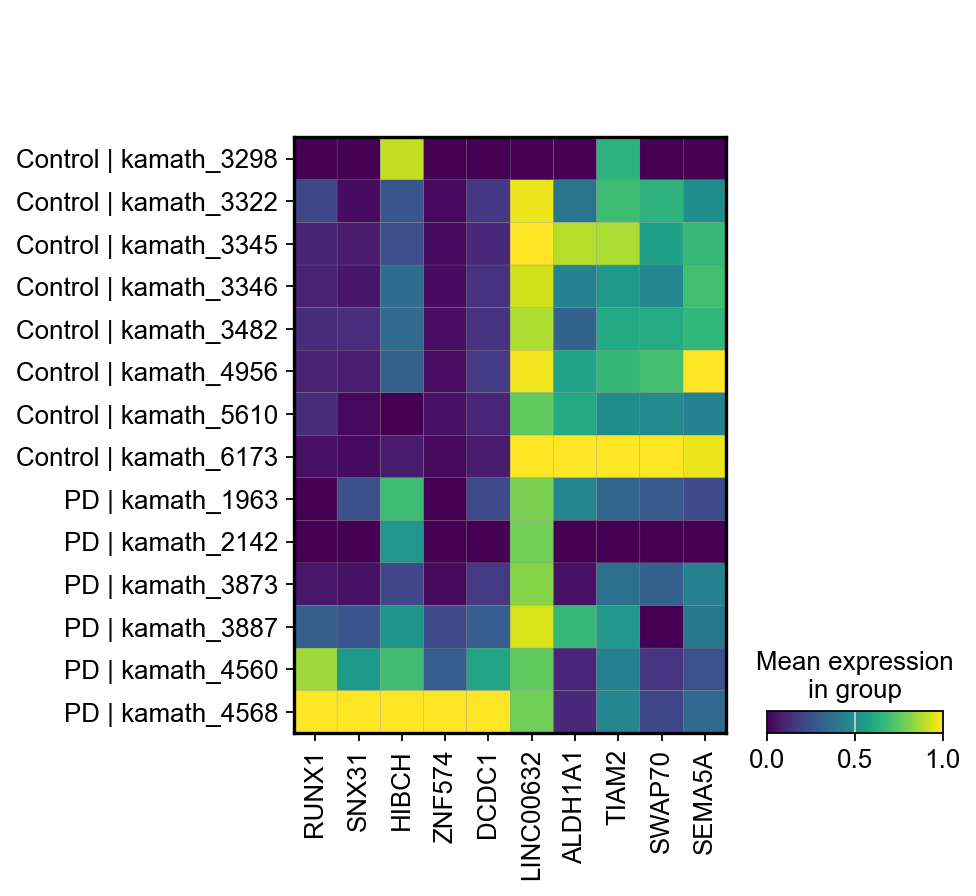

In [17]:
# Graphical view of top differentially expressed genes
top_genes = pd.concat([de_df.head(n_top), de_df.sort_values("scores").head(n_top)])["symbol"].tolist()
de.obs["donor"] = pd.Categorical(de.obs["condition_id"].astype(str) + " | " + de.obs["batch"].astype(str))
sc.pl.dotplot(de, top_genes, groupby="condition_id", gene_symbols="feature_name")
sc.pl.matrixplot(de, top_genes, groupby="donor", gene_symbols="feature_name", standard_scale="var")

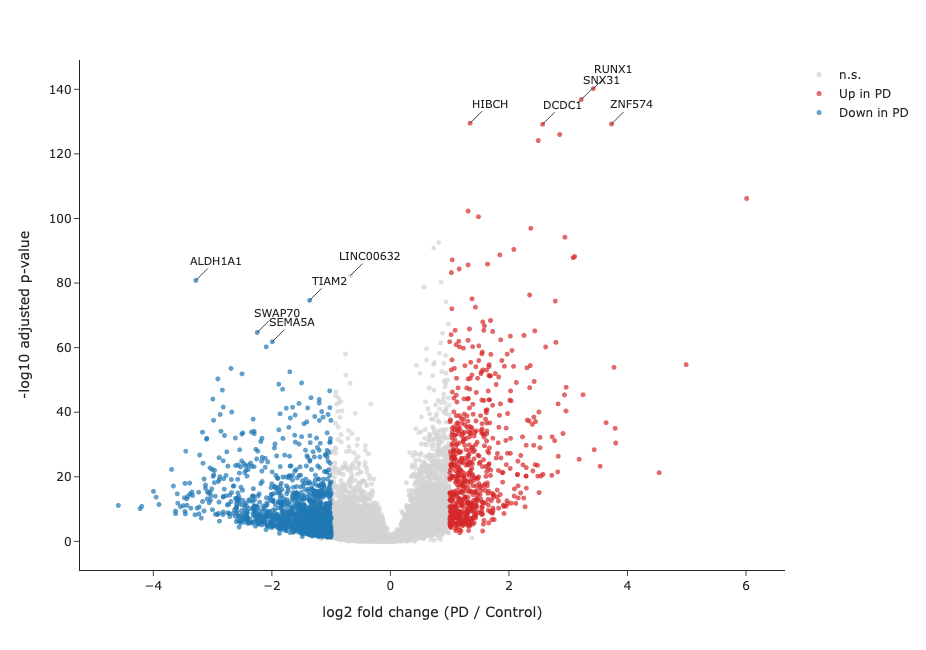

In [18]:
# Volcano plot (cell-level p-values; hover a point for its donor-level check)
up, down = f"Up in {test_group}", f"Down in {test_group}"
is_sig = de_df["pvals_adj"] < DE_FDR
volcano = de_df.assign(
    neg_log10_padj=-np.log10(de_df["pvals_adj"].clip(lower=np.finfo(float).tiny)),
    call=np.select([is_sig & (de_df["logfoldchanges"] >= DE_MIN_LFC),
                    is_sig & (de_df["logfoldchanges"] <= -DE_MIN_LFC)], [up, down], default="n.s."),
)

fig = px.scatter(
    volcano, x="logfoldchanges", y="neg_log10_padj", color="call",
    color_discrete_map={up: "#d62728", down: "#1f77b4", "n.s.": "lightgrey"},
    category_orders={"call": ["n.s.", up, down]},  # draw n.s. first, underneath
    hover_name="symbol",
    hover_data={"gene_id": True, "pvals_adj": ":.2e", "pct_nz_group": ":.2f",
                "donor_delta": ":.2f", "donor_mwu_pval": ":.3f",
                "logfoldchanges": ":.2f", "neg_log10_padj": False, "call": False},
    labels={"logfoldchanges": f"log2 fold change ({test_group} / {ref_group})",
            "neg_log10_padj": "-log10 adjusted p-value", "call": ""},
    render_mode="webgl", template="simple_white", width=800, height=650,
)
fig.update_traces(marker=dict(size=5, opacity=0.7))
for x in (-DE_MIN_LFC, DE_MIN_LFC):
    fig.add_vline(x=x, line_dash="dot", line_color="grey")
fig.add_hline(y=-np.log10(DE_FDR), line_dash="dot", line_color="grey")
for row in volcano[volcano["symbol"].isin(top_genes)].itertuples():
    fig.add_annotation(x=row.logfoldchanges, y=row.neg_log10_padj, text=row.symbol,
                       showarrow=True, arrowhead=0, ax=20, ay=-20, font=dict(size=11))
fig.show()